In [1]:
!pip install -q datasets

In [2]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("community-datasets/roman_urdu")
print(ds)

# The labels are stored as numbers, so get their names from the dataset itself
names = ds["train"].features["sentiment"].names
print(names)

df = ds["train"].to_pandas()
df["label"] = df["sentiment"].map(lambda i: names[i])
df.head()

README.md:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.06MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/20229 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'sentiment'],
        num_rows: 20229
    })
})
['Positive', 'Negative', 'Neutral']


,sentence,sentiment,label
0,Sai kha ya her kisi kay bus ki bat nhi hai lak...,0,Positive
1,sahi bt h,0,Positive
2,"Kya bt hai,",0,Positive
3,Wah je wah,0,Positive
4,Are wha kaya bat hai,0,Positive


In [3]:
df.shape

(20229, 3)

In [4]:
counts = df["label"].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))

label
Neutral     8929
Positive    6013
Negative    5287
Name: count, dtype: int64
label
Neutral     44.1
Positive    29.7
Negative    26.1
Name: count, dtype: float64


In [5]:
df["words"] = df["sentence"].str.split().str.len()
print(df["words"].describe())
df.sort_values("words").head(5)[["sentence", "label", "words"]]

count    20229.000000
mean        13.284493
std         13.447214
min          0.000000
25%          5.000000
50%          9.000000
75%         17.000000
max        301.000000
Name: words, dtype: float64


,sentence,label,words
8217,,Neutral,0
8219,,Neutral,0
8220,,Neutral,0
8082,,Neutral,0
8083,,Neutral,0


In [7]:
df.tail()

,sentence,sentiment,label,words
20224,Hamari jese awam teli laga k mazay leti,1,Negative,8
20225,Kaash hum b parhay likhay hotayKabhi likhtay g...,1,Negative,10
20226,Bahi sayasat kufrrr ha saaaf bttttt ha qanon s...,1,Negative,22
20227,aanti toh gussa e kr gai hain,1,Negative,7
20228,mai b sirf shadi kanry ki waja say imran khan ...,0,Positive,15


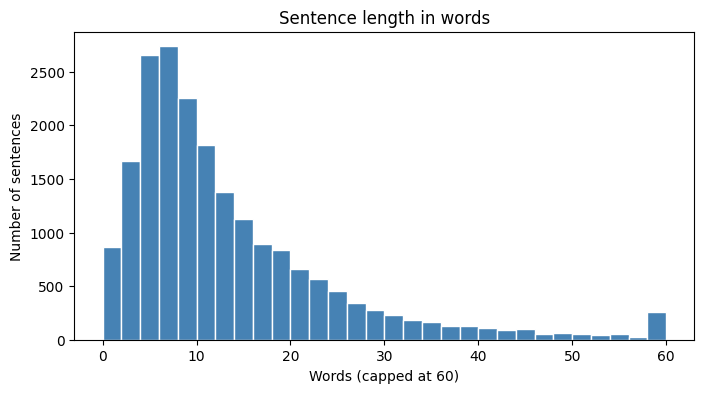

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["words"].clip(upper=60), bins=30, color="steelblue", edgecolor="white")
ax.set_title("Sentence length in words")
ax.set_xlabel("Words (capped at 60)")
ax.set_ylabel("Number of sentences")
plt.show()

In [9]:
print("Duplicate sentences:", df.duplicated(subset="sentence").sum())


Duplicate sentences: 568


In [10]:

# The same sentence with different labels is a sign of noisy labels
labels_per_sentence = df.groupby("sentence")["label"].nunique()
print("Sentences with conflicting labels:", (labels_per_sentence > 1).sum())

Sentences with conflicting labels: 22


In [11]:
df.sample(10, random_state=42)[["sentence", "label"]]

,sentence,label
19803,Lol ye waqt batye g kay Go PtI hota kay nawaz,Positive
14185,Is he bat py lanat ap k mou py,Negative
18533,20 AFRAAD KA QATEEL.,Negative
8917,nice,Neutral
10513,Ha bhenr ach akele mein chugli kru ity public ...,Negative
14461,Kon sa oil sarso ka oil..,Neutral
3474,Mickey arthur is not god of cricket team what ...,Positive
18012,Ssu camando physical test kB hn,Neutral
18993,Har ghari badal rhi hay..,Neutral
9842,Hamming Bird,Neutral


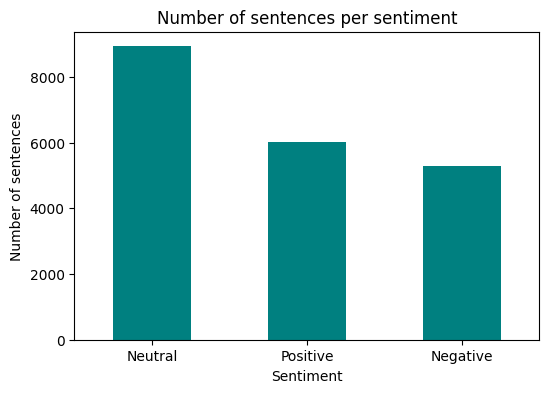

In [12]:
ax = counts.plot(kind="bar", figsize=(6, 4), color="teal")
ax.set_title("Number of sentences per sentiment")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of sentences")
plt.xticks(rotation=0)
plt.show()